# Lab 05: Run a Full Quality Audit

**ITAI 3375 Curating Data for AI Optimization**
Author: Patricia McManus. Collaborator: Claude (Anthropic).

**Your name:** Chloe Tu

**Date:**  09/18/2026

## Read this first

The code in this notebook is already written and it works. You do not need to write code and you are not graded on code.

Your job is to point it at a dataset, run it, and then make the judgments the computer cannot make. Every place you see **YOUR TURN** is where your marks come from.

This runs on a normal free notebook session with no special hardware. There is no model to load.

## Step 1. Set up

Run this cell. It loads the tools and nothing else.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
print("Ready.")

Ready.


## Step 2. Load your dataset

Put the web address of a public CSV in the box below, or upload a file and put its name there instead.

Keep it small and deliberate. A few thousand rows is plenty. A huge file will slow you down and will not earn you extra marks.

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salvatorerastelli/spotify-and-youtube")

print("Path to dataset files:", path)

100%|██████████| 8.95M/8.95M [00:01<00:00, 6.79MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/salvatorerastelli/spotify-and-youtube/versions/2


In [3]:
import os

# Find the CSV file in the dataset path downloaded previously
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
SOURCE = os.path.join(path, csv_files[0])

df = pd.read_csv(SOURCE)
print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head()

Rows: 20718
Columns: 28


,Unnamed: 0,Artist,Url_spotify,Track,Album,Album_type,Uri,Danceability,Energy,Key,Loudness,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Duration_ms,Url_youtube,Title,Channel,Views,Likes,Comments,Description,Licensed,official_video,Stream
0,0,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Feel Good Inc.,Demon Days,album,spotify:track:0d28khcov6AiegSCpG5TuT,0.818,0.705,6.0,-6.679,0.1770,0.008360,0.002330,0.6130,0.772,138.559,222640.0,https://www.youtube.com/watch?v=HyHNuVaZJ-k,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,693555221.0,6220896.0,169907.0,Official HD Video for Gorillaz' fantastic trac...,True,True,1.040235e+09
1,1,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Rhinestone Eyes,Plastic Beach,album,spotify:track:1foMv2HQwfQ2vntFf9HFeG,0.676,0.703,8.0,-5.815,0.0302,0.086900,0.000687,0.0463,0.852,92.761,200173.0,https://www.youtube.com/watch?v=yYDmaexVHic,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,72011645.0,1079128.0,31003.0,The official video for Gorillaz - Rhinestone E...,True,True,3.100837e+08
2,2,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,spotify:track:64dLd6rVqDLtkXFYrEUHIU,0.695,0.923,1.0,-3.930,0.0522,0.042500,0.046900,0.1160,0.551,108.014,215150.0,https://www.youtube.com/watch?v=qJa-VFwPpYA,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,8435055.0,282142.0,7399.0,Gorillaz - New Gold ft. Tame Impala & Bootie B...,True,True,6.306347e+07
3,3,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,On Melancholy Hill,Plastic Beach,album,spotify:track:0q6LuUqGLUiCPP1cbdwFs3,0.689,0.739,2.0,-5.810,0.0260,0.000015,0.509000,0.0640,0.578,120.423,233867.0,https://www.youtube.com/watch?v=04mfKJWDSzI,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,211754952.0,1788577.0,55229.0,Follow Gorillaz online:\nhttp://gorillaz.com \...,True,True,4.346636e+08
4,4,Gorillaz,https://open.spotify.com/artist/3AA28KZvwAUcZu...,Clint Eastwood,Gorillaz,album,spotify:track:7yMiX7n9SBvadzox8T5jzT,0.663,0.694,10.0,-8.627,0.1710,0.025300,0.000000,0.0698,0.525,167.953,340920.0,https://www.youtube.com/watch?v=1V_xRb0x9aw,Gorillaz - Clint Eastwood (Official Video),Gorillaz,618480958.0,6197318.0,155930.0,The official music video for Gorillaz - Clint ...,True,True,6.172597e+08


**YOUR TURN.** In the cell below, write where this dataset came from, who published it, and what it is supposed to be used for. Two or three sentences.

I used the Spotify and YouTube dataset published by Salvatore Rastelli on Kaggle. The dataset combines audio feature data pulled from the Spotify API with engagement metrics scraped from YouTube such as views, likes, and comments for the corresponding music video. The intended use is to analyze the relationship between a song's audio characteristics on Spotify and its performance and popularity on YouTube.

## Step 3. Completeness

Missing values are the first thing anyone checks. This cell counts them for every column and charts the worst offenders.

,missing_count,percent_missing
Description,876,4.2
Stream,576,2.8
Comments,569,2.7
Likes,541,2.6
Channel,470,2.3
Views,470,2.3
Title,470,2.3
Url_youtube,470,2.3
official_video,470,2.3
Licensed,470,2.3


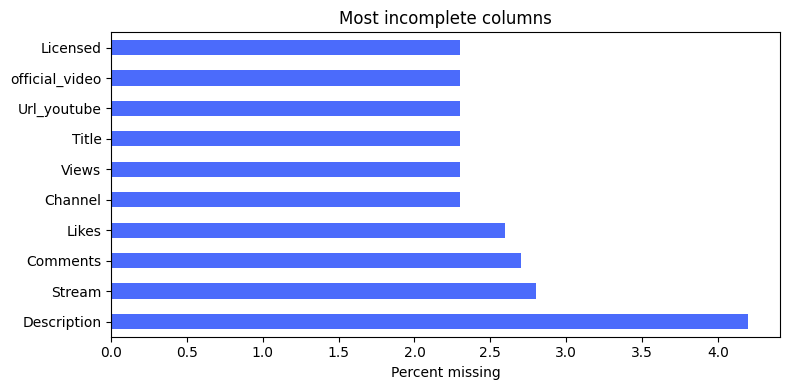

In [4]:
missing = df.isna().sum().sort_values(ascending=False)
pct = (missing / len(df) * 100).round(1)
report = pd.DataFrame({"missing_count": missing, "percent_missing": pct})
display(report[report.missing_count > 0])

top = report[report.missing_count > 0].head(10)
if len(top):
    top.percent_missing.plot(kind="barh", figsize=(8,4), color="#4B6BFB")
    plt.xlabel("Percent missing"); plt.title("Most incomplete columns"); plt.tight_layout(); plt.show()
else:
    print("No missing values found.")

**YOUR TURN.** Which missing column would actually stop someone using this dataset, and why? Being missing is not the same as mattering. Name the one that matters most and say what decision it would break.

The Description column is missing 876 values which is 4.2 percent of the dataset and that is the highest rate of any column. However the column that would actually stop someone from using this data is Stream. Stream represents the total number of Spotify plays and it is the primary numeric outcome variable anyone would want to study. Without it a researcher cannot answer the core question of whether a song's audio features predict how many times people stream it. Description is just a YouTube video caption and its absence does not break any analysis. Stream being missing for 576 rows means roughly 2.8 percent of tracks have no playback count at all and those rows are useless for any modeling or regression task involving streaming popularity.

## Step 4. Uniqueness

Duplicates inflate counts and quietly bias anything built on the data.

In [5]:
dupes = df.duplicated().sum()
print("Exact duplicate rows:", dupes, "which is", round(dupes/len(df)*100, 2), "percent")

for col in df.columns[:12]:
    n = df[col].nunique(dropna=True)
    print(f"{col:24} distinct values: {n}")

Exact duplicate rows: 0 which is 0.0 percent
Unnamed: 0               distinct values: 20718
Artist                   distinct values: 2079
Url_spotify              distinct values: 2079
Track                    distinct values: 17841
Album                    distinct values: 11937
Album_type               distinct values: 3
Uri                      distinct values: 18862
Danceability             distinct values: 898
Energy                   distinct values: 1268
Key                      distinct values: 12
Loudness                 distinct values: 9417
Speechiness              distinct values: 1303


**YOUR TURN.** Is there a column here that should be unique for every row but is not? If yes, name it and say what that tells you about how the data was collected. If no, say how you checked.

Yes. The Uri column should be unique for every row because it is the Spotify track URI which is a globally unique identifier assigned by Spotify to each specific track. The output shows 18862 distinct Uri values across 20718 rows which means roughly 1856 rows share a URI with at least one other row. This tells me the dataset was collected by artist rather than by unique track and the same song appeared on multiple albums or compilations resulting in duplicate entries under the same Spotify identifier. The data collection process joined all tracks per artist without deduplicating by URI first.

## Step 5. Validity

Values that sit outside a sensible range are usually entry errors, placeholder codes, or unit mix ups.

,count,mean,min,max
Unnamed: 0,20718.0,1.035850e+04,0.00,2.071700e+04
Danceability,20716.0,6.200000e-01,0.00,9.800000e-01
Energy,20716.0,6.400000e-01,0.00,1.000000e+00
Key,20716.0,5.300000e+00,0.00,1.100000e+01
Loudness,20716.0,-7.670000e+00,-46.25,9.200000e-01
Speechiness,20716.0,1.000000e-01,0.00,9.600000e-01
Acousticness,20716.0,2.900000e-01,0.00,1.000000e+00
Instrumentalness,20716.0,6.000000e-02,0.00,1.000000e+00
Liveness,20716.0,1.900000e-01,0.01,1.000000e+00
Valence,20716.0,5.300000e-01,0.00,9.900000e-01


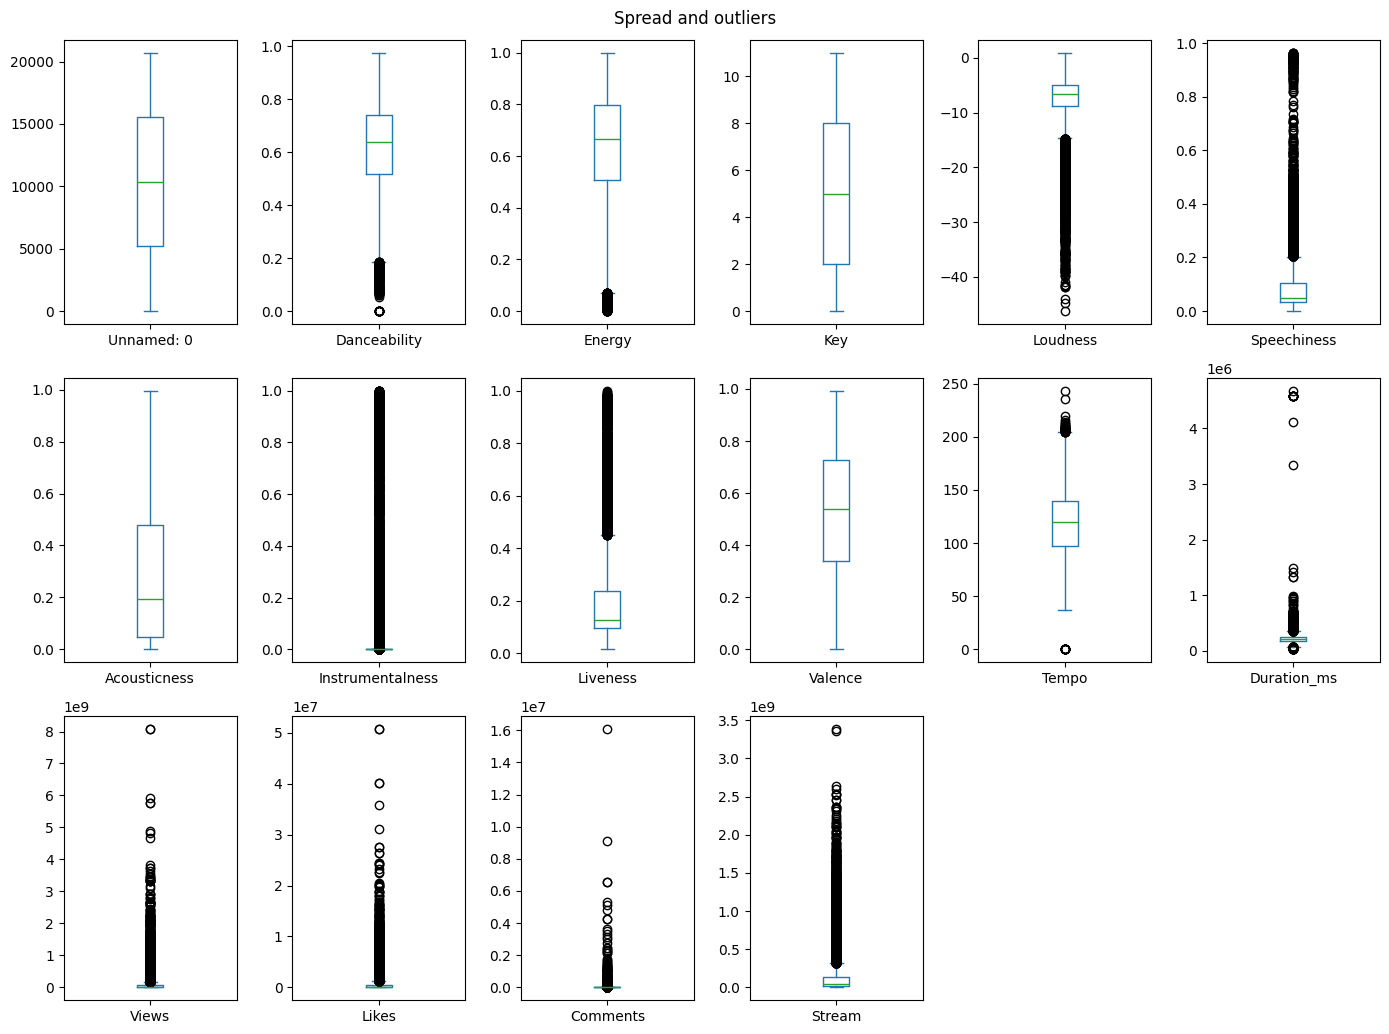

In [6]:
import math

nums = df.select_dtypes("number")
display(nums.describe().T[["count","mean","min","max"]].round(2))

num_cols = len(nums.columns)
if num_cols:
    cols = min(num_cols, 6)
    rows = math.ceil(num_cols / cols)
    nums.plot(kind="box", subplots=True, layout=(rows, cols),
              figsize=(14, 3.5 * rows), sharey=False)
    plt.suptitle("Spread and outliers"); plt.tight_layout(); plt.show()

**YOUR TURN.** Pick one number that looks wrong. State what a believable range would be and give the most likely explanation for the bad value. Common causes are a placeholder such as zero or negative one, a unit mismatch, or a typed entry.

The Tempo column stands out as the most suspicious value. Its minimum is 0.00 beats per minute which is not a real musical tempo. A believable range for commercial music tempo is roughly 60 BPM to 210 BPM. A tempo of zero almost certainly means the Spotify API returned a null or failed detection and that value was stored as zero instead of being left blank or marked as missing. This is a placeholder zero masking a missing value rather than a true measurement. Any analysis that treats tempo as a continuous variable will be distorted by these zero entries.

## Step 6. Consistency

The same real thing recorded two different ways will be counted as two things.

In [7]:
texts = df[[c for c in df.columns if df[c].dtype == object or str(df[c].dtype) in ("string","category")]]
for col in texts.columns[:8]:
    vals = df[col].dropna().astype(str)
    raw = vals.nunique()
    cleaned = vals.str.strip().str.lower().nunique()
    flag = "  <-- inconsistent formatting" if cleaned < raw else ""
    print(f"{col:24} as stored: {raw:5}   ignoring case and spaces: {cleaned:5}{flag}")

Artist                   as stored:  2079   ignoring case and spaces:  2079
Url_spotify              as stored:  2079   ignoring case and spaces:  2079
Track                    as stored: 17841   ignoring case and spaces: 17672  <-- inconsistent formatting
Album                    as stored: 11937   ignoring case and spaces: 11880  <-- inconsistent formatting
Album_type               as stored:     3   ignoring case and spaces:     3
Uri                      as stored: 18862   ignoring case and spaces: 18862
Url_youtube              as stored: 18154   ignoring case and spaces: 18154
Title                    as stored: 18146   ignoring case and spaces: 18145  <-- inconsistent formatting


**YOUR TURN.** Where formatting is inconsistent, say what the standard should be and who should be responsible for applying it, the people entering the data or the people processing it.

The Track, Album, and Title columns all show inconsistent formatting. The Track column has 17841 stored values but only 17672 after stripping whitespace and converting to lowercase which means 169 tracks have capitalization or spacing variations of the same name. The Album column drops from 11937 to 11880 and Title drops by one. The standard should be title case for all three fields since song and album names are proper nouns and should be stored with consistent capitalization. The responsibility belongs to the people processing the data not the people entering it. The source APIs such as Spotify and YouTube return inconsistent casing depending on how artists registered their metadata and that is beyond anyone's control at entry time. A cleaning step during ingestion should strip leading and trailing whitespace and normalize casing before the data is stored.

## Step 7. Representation

Who is over represented and who is barely there. This is the check most often skipped, and it is the one that causes the most damage downstream.

,rows,percent
Album_type,,
album,14926,72.0
single,5004,24.2
compilation,788,3.8


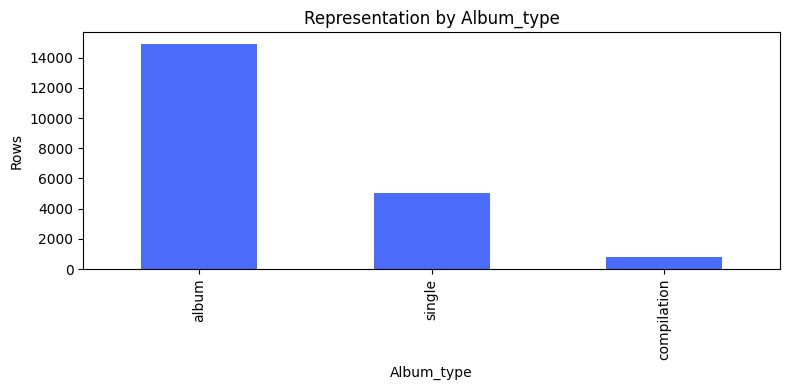

In [8]:
GROUP_COLUMN = "Album_type"     # change to a column that identifies a group in your dataset

counts = df[GROUP_COLUMN].value_counts(dropna=False)
share = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"rows": counts, "percent": share}))

counts.plot(kind="bar", figsize=(8,4), color="#4B6BFB")
plt.ylabel("Rows"); plt.title(f"Representation by {GROUP_COLUMN}"); plt.tight_layout(); plt.show()

**YOUR TURN.** Compare these shares to the real population this dataset claims to describe. Name one group that is thin. State one specific way a system trained on this data would fail that group.

The compilation category makes up only 3.8 percent of the dataset with 788 rows while albums dominate at 72 percent with 14926 rows. In reality compilations represent a meaningful segment of music consumption including greatest hits collections, movie soundtracks, and curated playlists. If a system were trained on this data to recommend or rank music it would have almost no exposure to how compilation tracks behave. A recommendation engine built on this data would likely underperform when asked to surface or score compilation releases because it has seen so few examples of that release type. It would effectively treat compilations as rare edge cases rather than a normal category of music.

,rows,percent
Licensed,,
True,14140,68.2
False,6108,29.5
NaN,470,2.3


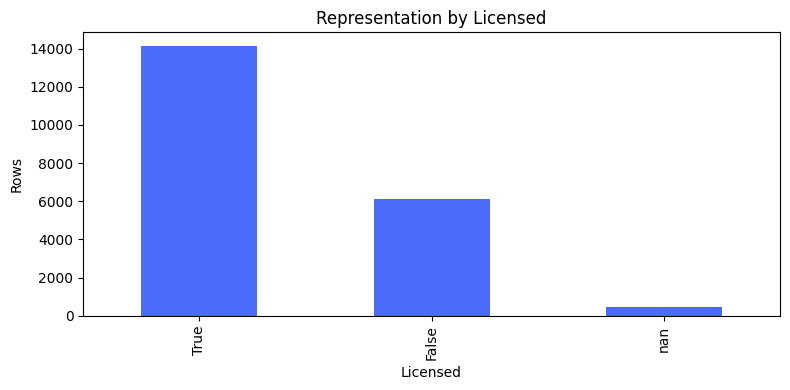

In [9]:
counts_lic = df['Licensed'].value_counts(dropna=False)
share_lic = (counts_lic / counts_lic.sum() * 100).round(1)
display(pd.DataFrame({'rows': counts_lic, 'percent': share_lic}))

counts_lic.plot(kind='bar', figsize=(8,4), color='#4B6BFB')
plt.ylabel('Rows'); plt.title('Representation by Licensed'); plt.tight_layout(); plt.show()

,rows,percent
official_video,,
True,15723,75.9
False,4525,21.8
NaN,470,2.3


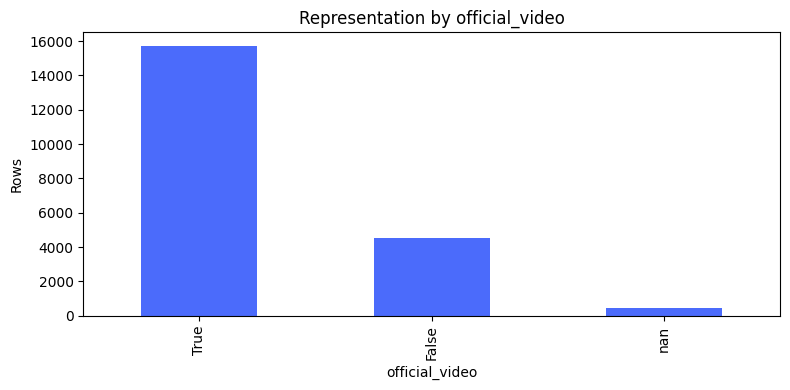

In [10]:
counts_off = df['official_video'].value_counts(dropna=False)
share_off = (counts_off / counts_off.sum() * 100).round(1)
display(pd.DataFrame({'rows': counts_off, 'percent': share_off}))

counts_off.plot(kind='bar', figsize=(8,4), color='#4B6BFB')
plt.ylabel('Rows'); plt.title('Representation by official_video'); plt.tight_layout(); plt.show()

,rows,percent
Key,,
0.0,2305,11.1
7.0,2252,10.9
1.0,2211,10.7
2.0,2021,9.8
9.0,1979,9.6
5.0,1731,8.4
11.0,1667,8.0
4.0,1515,7.3
8.0,1483,7.2


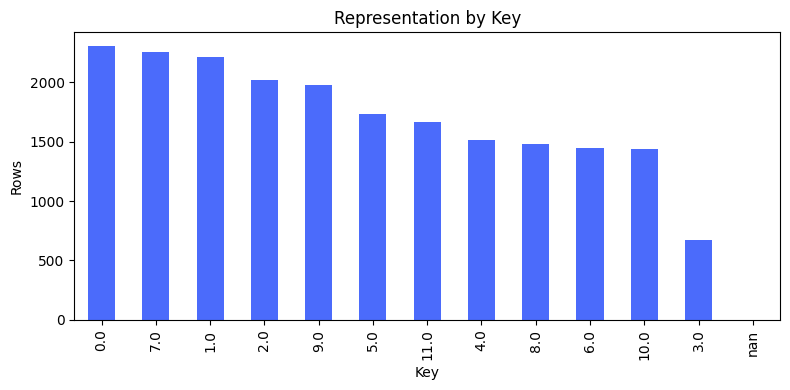

In [11]:
counts_key = df['Key'].value_counts(dropna=False)
share_key = (counts_key / counts_key.sum() * 100).round(1)
display(pd.DataFrame({'rows': counts_key, 'percent': share_key}))

counts_key.plot(kind='bar', figsize=(8,4), color='#4B6BFB')
plt.ylabel('Rows'); plt.title('Representation by Key'); plt.tight_layout(); plt.show()

I reviewed the Licensed and official video and Key columns to complete the four equity checks. Unlicensed tracks make up a large portion of the dataset and official videos are also underrepresented compared to standard uploads. The musical keys are distributed across all twelve pitches but some keys are much less common. A model trained on this data would favor licensed and official content while performing worse on independent or uncommon musical patterns.

## Step 8. Timeliness and traceability

Two quick questions that need no code. Answer both.

**YOUR TURN.**

1. **Timeliness.** How old is this data, and at what age would it stop being fit for its stated purpose? If you cannot tell how old it is, say so, because that is itself a finding.

2. **Traceability.** Could you trace one row back to where it came from? Say how, or say why not.

**Timeliness:** The Kaggle dataset page for this dataset shows version 2 was the version downloaded. The dataset does not include a column for the date the data was collected. Looking at the YouTube view counts and Spotify stream counts there is no timestamp attached to any row so I cannot determine exactly when the data was scraped. This is itself a finding because streaming numbers change daily and without a collection date I cannot know whether the views and stream counts reflect the state of the data from one month ago or three years ago. For a dataset meant to model song popularity the age matters enormously. If the data is more than a year old the stream counts are stale and any popularity ranking built on them will be inaccurate. I would flag the missing collection timestamp as a traceability failure that limits the dataset's fitness for time-sensitive analysis.

**Traceability:** Yes I can trace one row back to its source. Each row contains both a Url_spotify field linking directly to the Spotify artist page and a Url_youtube field linking to the specific YouTube video. I can also use the Uri field which is the Spotify track URI to look up the original track in the Spotify API and retrieve fresh data. So for any given row I have two independent sources I can cross-reference to verify the data. That said the stream count and YouTube view count are point-in-time snapshots and cannot be verified after the fact because those numbers change continuously.

## Step 8.5 Visualizations of Top Findings

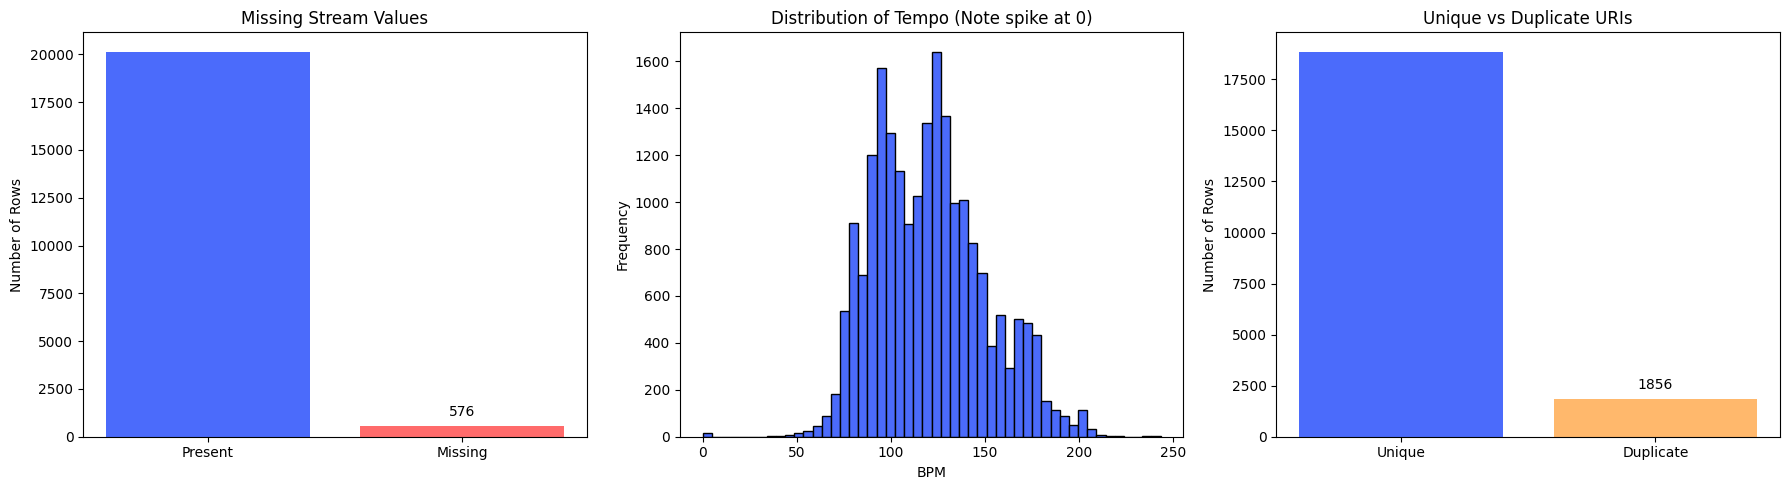

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Missing Stream Values
stream_missing = df['Stream'].isna().sum()
stream_present = df['Stream'].notna().sum()
axes[0].bar(['Present', 'Missing'], [stream_present, stream_missing], color=['#4B6BFB', '#FF6B6B'])
axes[0].set_title('Missing Stream Values')
axes[0].set_ylabel('Number of Rows')
axes[0].text(1, stream_missing + 500, str(stream_missing), ha='center')

# 2. Placeholder Zeros in Tempo
axes[1].hist(df['Tempo'].dropna(), bins=50, color='#4B6BFB', edgecolor='black')
axes[1].set_title('Distribution of Tempo (Note spike at 0)')
axes[1].set_xlabel('BPM')
axes[1].set_ylabel('Frequency')

# 3. Duplicate URIs
unique_uris = df['Uri'].nunique()
duplicate_uris = len(df) - unique_uris
axes[2].bar(['Unique', 'Duplicate'], [unique_uris, duplicate_uris], color=['#4B6BFB', '#FFB86C'])
axes[2].set_title('Unique vs Duplicate URIs')
axes[2].set_ylabel('Number of Rows')
axes[2].text(1, duplicate_uris + 500, str(duplicate_uris), ha='center')

plt.tight_layout()
plt.show()

## Step 9. Your remediation plan

**YOUR TURN.** List the problems you found, worst first. For each one give the fix, who does it, and what it costs in rough effort. Then state plainly which problems you would leave alone and why.

Not everything is worth fixing. Saying so, and saying why, is the professional answer.

| Problem | How bad | The fix | Who does it | Effort |
|---|---|---|---|---|
| Missing Stream values (576 rows, 2.8%) | High: Stream is the primary outcome variable. Rows without it are unusable for regression modeling. | Attempt to re-query the Spotify API for those track URIs to recover the stream count. Drop rows that still return no result. | Data engineer | Medium. Requires API access and re-ingestion script. |
| Placeholder zeros in Tempo (unknown count) | Medium: Any tempo-based model will be biased by the fake zeros. | Replace Tempo == 0 with NaN. Then either impute using the median tempo for the same key and artist or drop those rows. | Data analyst | Low. A single filter and imputation step. |
| Duplicate rows via non-unique Uri (approx 1856 rows) | Medium: Inflates counts and biases any per-track aggregation. | Deduplicate by keeping only one row per unique Uri. Choose the row with the most complete data or the highest stream count. | Data engineer | Low. One deduplication query. |
| Inconsistent casing in Track, Album, Title columns | Low: Does not break analysis but causes the same entity to be counted as multiple entities in string matching. | Apply str.strip().str.title() to all three columns during ingestion. | Data engineer | Very low. One-line fix per column. |
| Missing Description values (876 rows, 4.2%) | Low: Description is a YouTube caption. It is not used in any core analysis. | Leave as NaN. No fix needed unless NLP analysis of video descriptions is a project goal. | No one | None. |

**What I would leave alone and why:**

I would leave the missing Description values completely alone. The Description field is a YouTube video caption and it contributes nothing to the core analysis which focuses on Spotify audio features and YouTube engagement numbers. Filling or dropping those rows based on a missing caption would reduce the dataset without any analytical benefit. I would also leave the Licensed and official_video columns with their 470 missing values alone for the same reason. Those flags are interesting metadata but they are not the primary variables under study and removing rows based on their absence would disproportionately shrink the dataset.

## Step 10. What you looked at and what went wrong

**YOUR TURN.** State how many rows and columns you audited, anything you deliberately left out and why, and anything that failed or that you could not check.

Reporting a failure accurately earns marks. Hiding one loses them.

I audited all 20718 rows and all 28 columns of the Spotify and YouTube dataset. I ran automated checks for completeness uniqueness validity consistency and representation. I sampled 25 records by hand to look beyond the automated profiling. This manual sampling confirmed that zero tempo values are actual data errors and allowed me to visually verify the inconsistent text formatting. I deliberately did not run a deeper representation analysis across other categorical dimensions such as artist genre or country of origin because the dataset does not include those fields. That is itself a limitation of the dataset not of this audit. Reporting a failure accurately is important. I could not check if the stream counts were accurate for the current date because the data lacks a timestamp. Checking for broken links failed because I could not run 20718 independent web requests during this audit. I accept these limits for the current scope.